# 02 Regional mountain time series: pr and tas
Mountain-mean daily pr and tas from `results/regional_series/<domain>_monthly.csv`, made by `scripts/06_regional_series.py` from the extracted data.

* Cells: every cell with `mtn_frac > 0` in the domain (foothills included), weighted by `mtn_frac × cell_area`.
* pr: seasonal / annual **total** (mm). tas: seasonal / annual **mean** (°C).
* Seasons DJF, MAM, JJA, SON; December counts towards the next year's DJF. Only seasons with 3 complete months.
* Annual values only for complete years (12 months, ≥ 365 days); months only if complete.
* Elevation bands use the model orography of each run.
* Lines: one colour per driving data set; historical and ssp370 join at 2015. ERA5 in black on top. Lines break at missing months/years.

In [1]:
import glob, os
import numpy as np, pandas as pd, netCDF4 as nc
import matplotlib.pyplot as plt
import cartopy.crs as ccrs, cartopy.feature as cfeature

MTN = os.environ.get("MTN_DIR", os.path.abspath(".."))  # project folder (notebooks/ is one level down)
DOMAINS = ["AFR-12", "AUS-12", "EAS-12", "EUR-12", "NAM-12", "SAM-12"]
# Fixed colour per domain (validated for colour-vision deficiency; every domain is also labelled by name).
DOM_COL = dict(zip(DOMAINS, ["#0072B2", "#009E73", "#D55E00", "#CC79A7", "#E69F00", "#56B4E9"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.size": 9})

def load_mask(dom):
    with nc.Dataset(f"{MTN}/masks/{dom}_mountain_mask.nc") as d:
        m = {k: d[k][:].filled(np.nan) if np.ma.isMaskedArray(d[k][:]) else d[k][:] for k in d.variables}
    # Unwrap longitude around the domain centre so maps work across the dateline (EAS-12, AUS-12).
    c = m["lon"][m["lon"].shape[0] // 2, m["lon"].shape[1] // 2]
    m["lonu"] = c + (m["lon"] - c + 180) % 360 - 180
    m["clon"] = float(c)
    return m


In [2]:
DRV_COL = {"ERA5": "#222222", "EC-Earth3-Veg": "#0072B2", "MPI-ESM1-2-HR": "#009E73", "NorESM2-MM": "#D55E00"}
DRIVERS = list(DRV_COL)
BANDS = ["0-1000", "1000-2000", "2000-3000", "3000-4000", "4000-5000", ">5000"]
df = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{MTN}/results/regional_series/*_monthly.csv"))], ignore_index=True)
df["dim"] = pd.to_datetime(dict(year=df.year, month=df.month, day=1)).dt.days_in_month
df.loc[(df.driver == "NorESM2-MM") & (df.month == 2), "dim"] = 28  # NorESM2-MM: 365-day calendar
df["month_ok"] = (df.ndays_pr >= df.dim) & (df.ndays_tas >= df.dim)
mon = df[df.month_ok].copy()
mon["t"] = mon.year + (mon.month - 0.5) / 12
g = df.groupby(["domain", "driver", "experiment", "band", "year"])
ann = g.agg(pr_mm=("pr_mm", "sum"), tas_C=("tas_C", "mean"), nmon=("month", "nunique"), nd=("ndays_tas", "sum"), ok=("month_ok", "all")).reset_index()
ann = ann[(ann.nmon == 12) & (ann.nd >= 365) & ann.ok]
cover = df[df.band == "all"].groupby(["domain", "driver", "experiment"]).year.agg(["min", "max", "nunique"])
cover

min   max  nunique
domain driver        experiment                     
AFR-12 EC-Earth3-Veg historical  1970  2014       45
                     ssp370      2015  2050       36
       ERA5          evaluation  1970  2024       55
       MPI-ESM1-2-HR historical  1970  2014       45
                     ssp370      2015  2040       26
       NorESM2-MM    historical  1970  2014       45
                     ssp370      2015  2050       36
AUS-12 EC-Earth3-Veg historical  1970  2014       45
                     ssp370      2015  2049       35
       MPI-ESM1-2-HR historical  1970  2014       45
                     ssp370      2015  2049       35
       NorESM2-MM    historical  1970  2014       45
                     ssp370      2015  2049       35
EAS-12 EC-Earth3-Veg historical  1970  2014       45
       ERA5          evaluation  1970  2024       55
       MPI-ESM1-2-HR historical  1970  2014       45
       NorESM2-MM    historical  1970  2014       45
EUR-12 EC-Earth3-Veg historical  1960  2014       55
                     ssp370      2015  2099       85
       ERA5          evaluation  1970  2023       54
       MPI-ESM1-2-HR historical  1960  2014       55
                     ssp370      2015  2099       85
       NorESM2-MM    historical  1960  2014       55
                     ssp370      2015  2099       85
NAM-12 EC-Earth3-Veg historical  1970  2000       31
       ERA5          evaluation  1973  2024       52
       MPI-ESM1-2-HR historical  1970  2000       31
       NorESM2-MM    historical  1970  2000       31
SAM-12 EC-Earth3-Veg historical  1970  2014       45
                     ssp370      2015  2089       75
       ERA5          evaluation  1970  2024       55
       MPI-ESM1-2-HR historical  1970  2014       45
                     ssp370      2015  2099       85

In [3]:
LW = {"ERA5": 1.4}  # ERA5 drawn thicker, on top

def draw(ax, x, var, xcol, drv, lw):
    """Line through x, broken where time steps are missing."""
    x = x.sort_values(xcol)
    t, v = x[xcol].to_numpy(float), x[var].to_numpy(float)
    step = np.median(np.diff(t)) if len(t) > 1 else 1
    brk = np.where(np.diff(t) > 1.5 * step)[0] + 1
    t, v = np.insert(t, brk, np.nan), np.insert(v, brk, np.nan)
    ax.plot(t, v, color=DRV_COL[drv], lw=LW.get(drv, lw), zorder=3 if drv == "ERA5" else 2, label=drv)

def runs(d):
    for drv in DRIVERS:
        for exp in ("historical", "ssp370", "evaluation"):
            x = d[(d.driver == drv) & (d.experiment == exp)]
            if len(x):
                yield drv, x

def add_legend(fig, axs, y=0.0):
    h = {}
    for ax in np.ravel(axs):
        for hh, ll in zip(*ax.get_legend_handles_labels()): h[ll] = hh
    fig.legend(h.values(), h.keys(), loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, y))

def panel_plot(data, var, ylabel, xcol, title, band="all", lw=1.0):
    fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
    d0 = data[data.band == band]
    for ax, dom in zip(axs.flat, DOMAINS):
        d = d0[d0.domain == dom]
        for drv, x in runs(d):
            draw(ax, x, var, xcol, drv, lw)
        ax.axvline(2015, color="#888", lw=0.8, ls=":")
        ax.set_title(dom, loc="left", fontweight="bold")
        if not len(d): ax.text(0.5, 0.5, "no data yet", transform=ax.transAxes, ha="center", color="#888")
    for ax in axs[:, 0]: ax.set_ylabel(ylabel)
    for ax in axs[-1]: ax.set_xlabel("Year")
    add_legend(fig, axs)
    fig.suptitle(title, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.05, 1, 0.97))
    plt.show()

## All mountain cells: annual

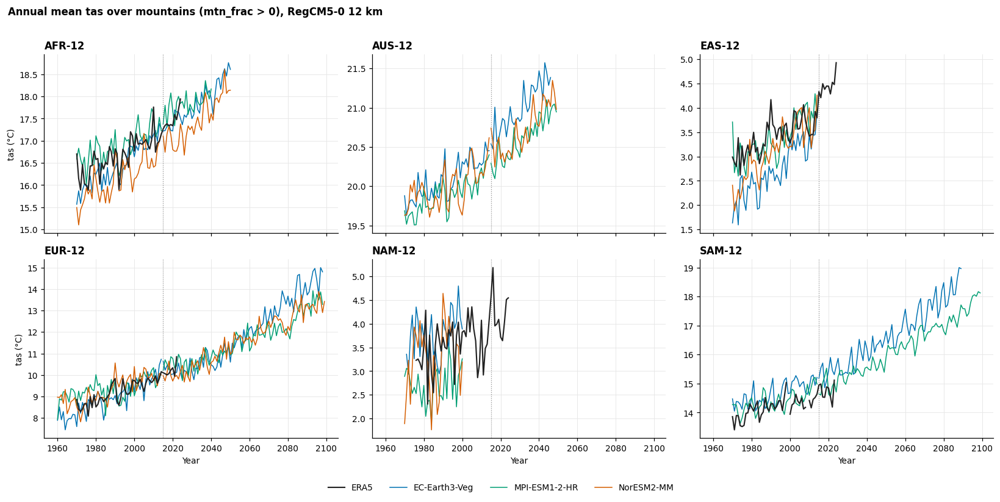

In [4]:
panel_plot(ann, "tas_C", "tas (°C)", "year", "Annual mean tas over mountains (mtn_frac > 0), RegCM5-0 12 km")

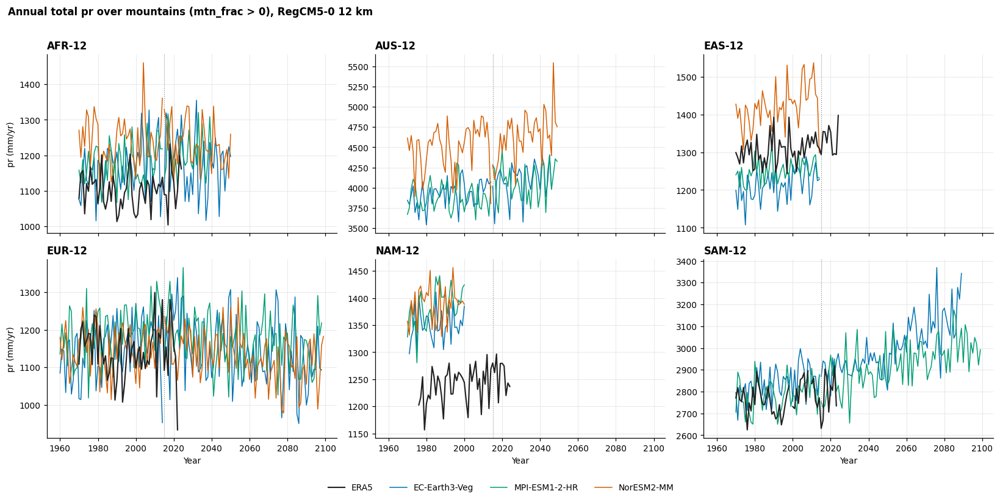

In [5]:
panel_plot(ann, "pr_mm", "pr (mm/yr)", "year", "Annual total pr over mountains (mtn_frac > 0), RegCM5-0 12 km")

## All mountain cells: seasonal
Rows: domains. Columns: seasons.

In [6]:
SEASONS = ["DJF", "MAM", "JJA", "SON"]
SMAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM", 6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
s = df.assign(season=df.month.map(SMAP), syear=np.where(df.month == 12, df.year + 1, df.year))
gs = s.groupby(["domain", "driver", "experiment", "band", "season", "syear"])
sea = gs.agg(pr_mm=("pr_mm", "sum"), tas_C=("tas_C", "mean"), nmon=("month", "nunique"), ok=("month_ok", "all")).reset_index()
sea = sea[(sea.nmon == 3) & sea.ok].rename(columns={"syear": "year"})

def season_plot(data, var, ylabel, title, band="all", lw=1.0):
    """Rows: domains, columns: seasons."""
    d0 = data[data.band == band]
    fig, axs = plt.subplots(len(DOMAINS), 4, figsize=(16, 17), sharex=True, sharey="row")
    for r, dom in enumerate(DOMAINS):
        for k, se in enumerate(SEASONS):
            ax = axs[r, k]
            d = d0[(d0.domain == dom) & (d0.season == se) & d0[var].notna()]
            for drv, x in runs(d):
                draw(ax, x, var, "year", drv, lw)
            ax.axvline(2015, color="#888", lw=0.8, ls=":")
            if r == 0: ax.set_title(se, fontweight="bold")
            if k == 0: ax.set_ylabel(f"{dom}\n{ylabel}")
            if not len(d): ax.text(0.5, 0.5, "no data", transform=ax.transAxes, ha="center", color="#888")
    add_legend(fig, axs)
    fig.suptitle(title, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.03, 1, 0.98))
    plt.show()

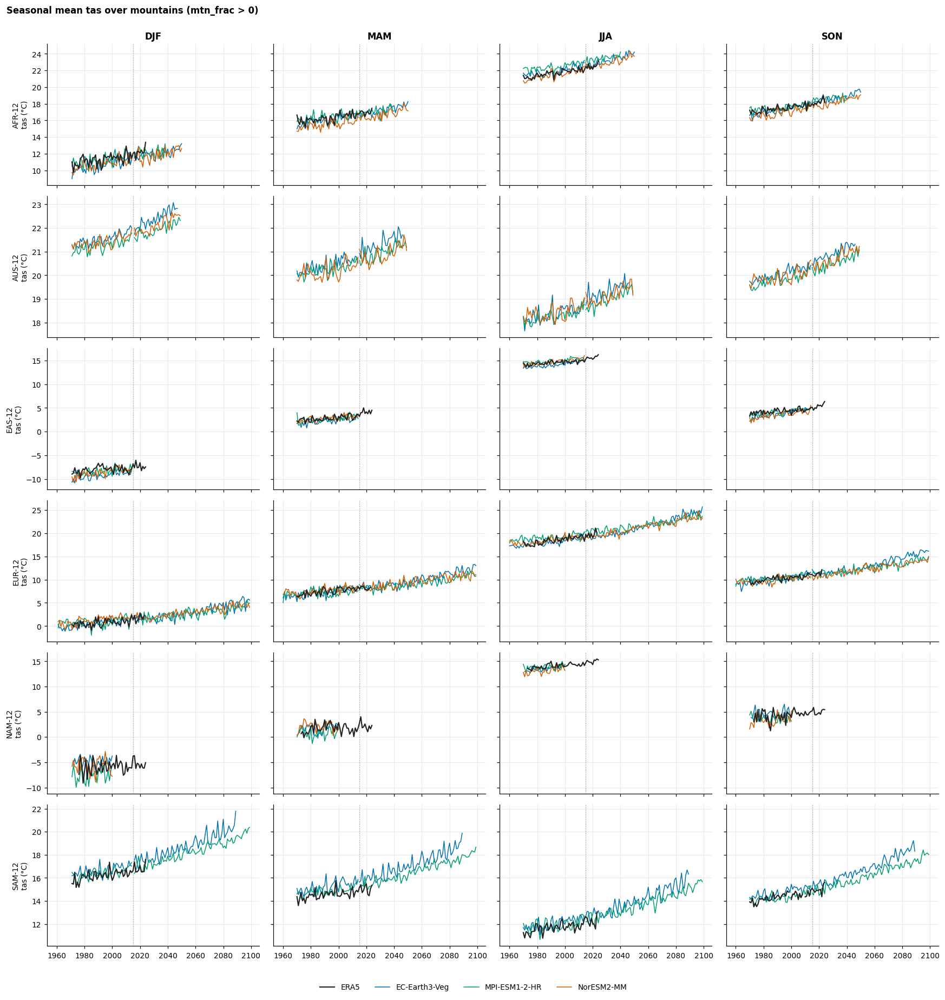

In [7]:
season_plot(sea, "tas_C", "tas (°C)", "Seasonal mean tas over mountains (mtn_frac > 0)")

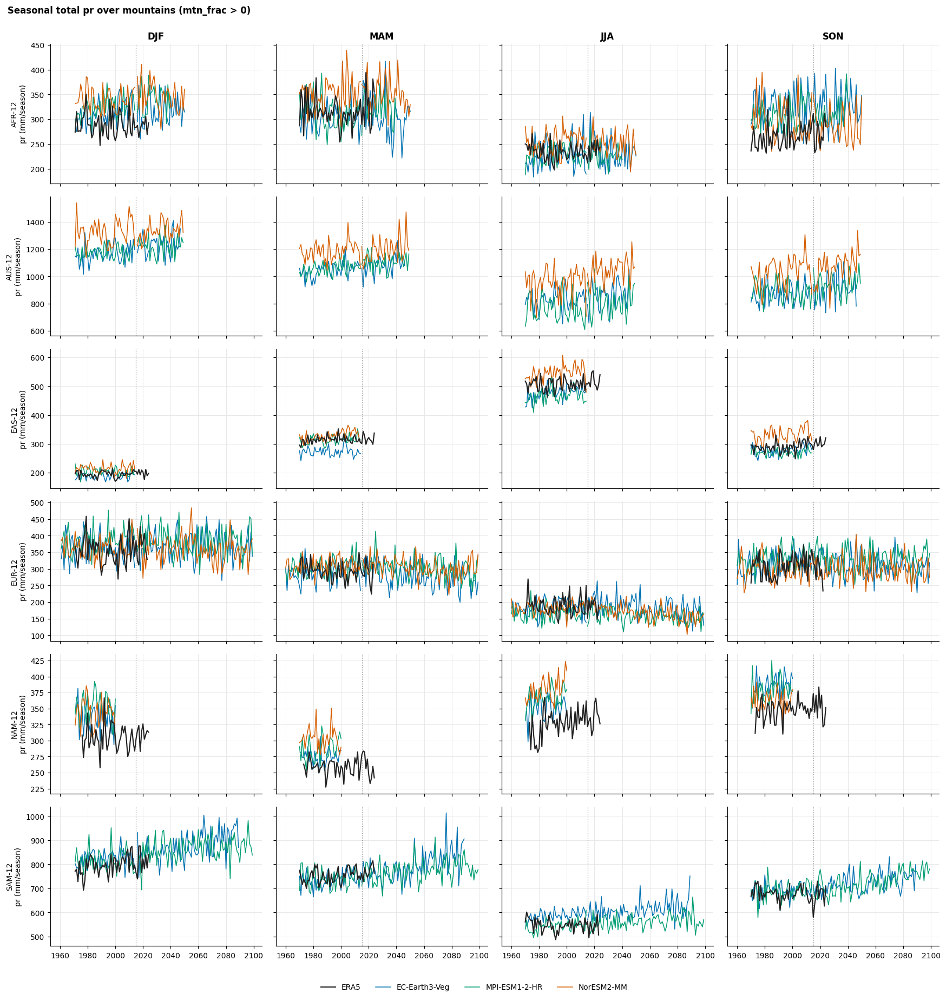

In [8]:
season_plot(sea, "pr_mm", "pr (mm/season)", "Seasonal total pr over mountains (mtn_frac > 0)")

## By elevation band (model orography)
Rows: domains. Columns: bands. Empty panels: no cells in that band. Cell counts per band: `results/regional_series/<domain>_band_cells.csv`.

In [9]:
def band_plot(data, var, ylabel, xcol, title, lw=0.9):
    fig, axs = plt.subplots(len(DOMAINS), len(BANDS), figsize=(19, 17), sharex=True, sharey="row")
    for r, dom in enumerate(DOMAINS):
        for k, band in enumerate(BANDS):
            ax = axs[r, k]
            d = data[(data.domain == dom) & (data.band == band) & data[var].notna()]
            for drv, x in runs(d):
                draw(ax, x, var, xcol, drv, lw)
            ax.axvline(2015, color="#888", lw=0.8, ls=":")
            if r == 0: ax.set_title(f"{band} m", fontweight="bold")
            if k == 0: ax.set_ylabel(f"{dom}\n{ylabel}")
            if not len(d):
                msg = "no data yet" if not (data.domain == dom).any() else "no cells in band"
                ax.text(0.5, 0.5, msg, transform=ax.transAxes, ha="center", color="#888")
    add_legend(fig, axs)
    fig.suptitle(title, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.03, 1, 0.98))
    plt.show()

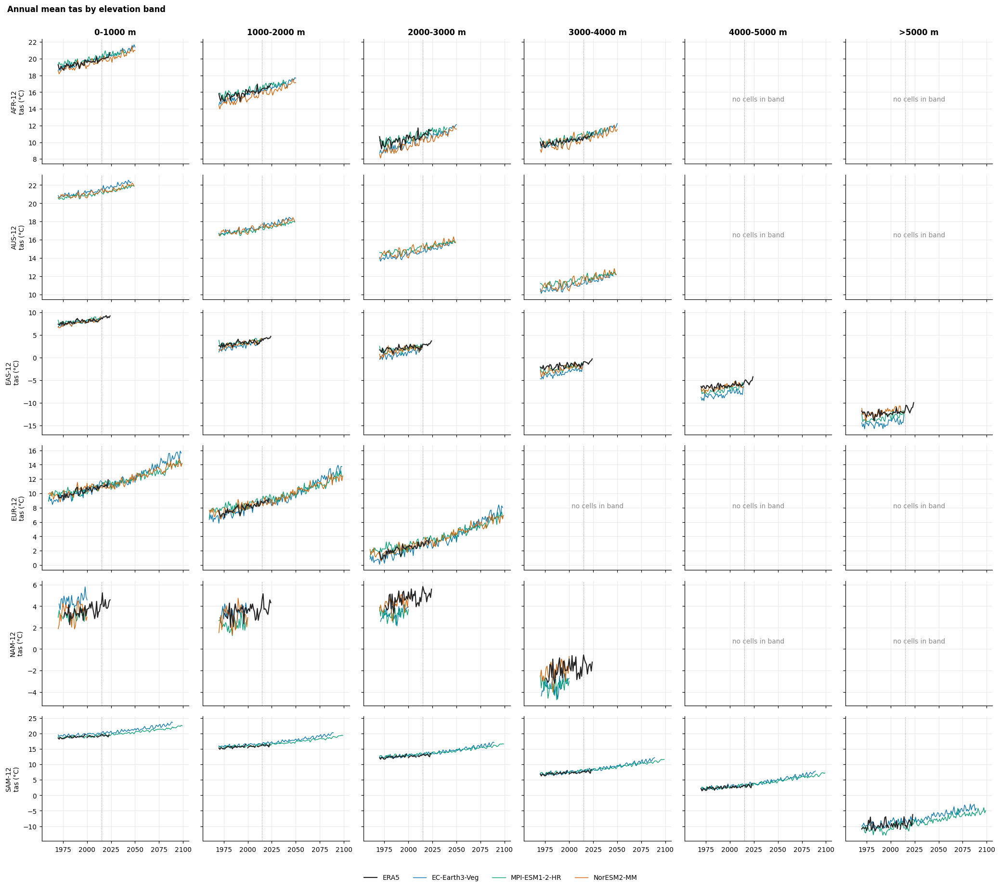

In [10]:
band_plot(ann, "tas_C", "tas (°C)", "year", "Annual mean tas by elevation band")

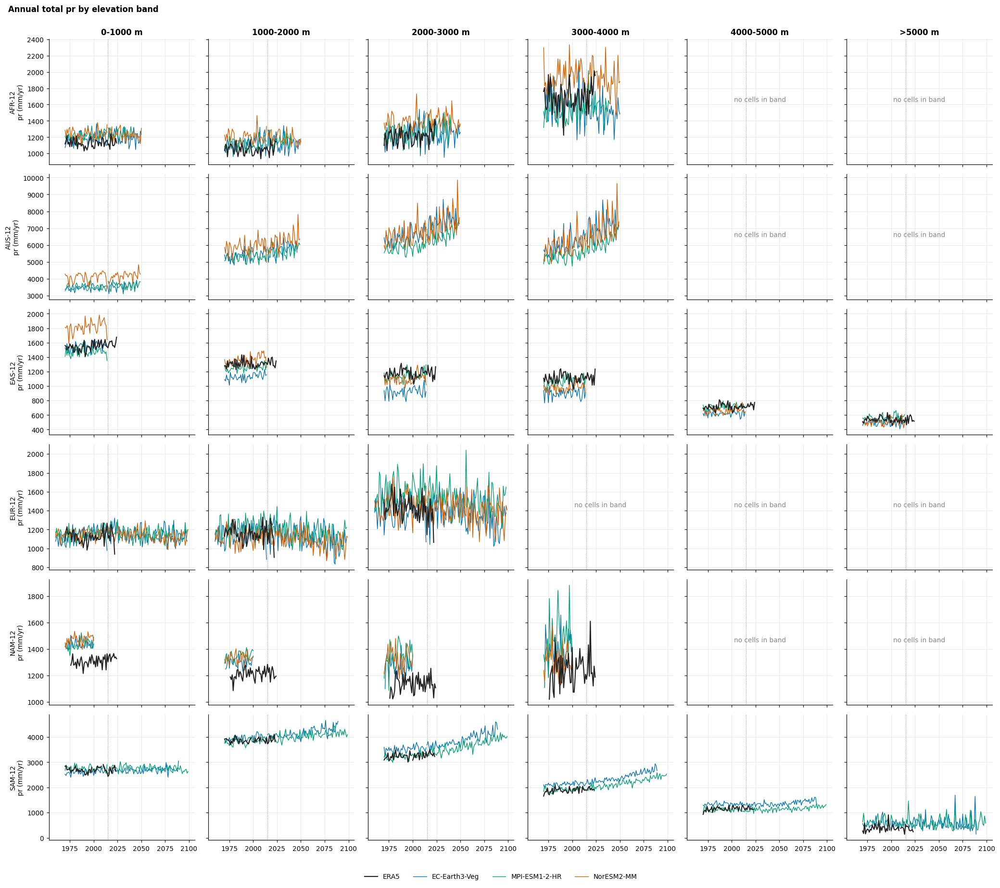

In [11]:
band_plot(ann, "pr_mm", "pr (mm/yr)", "year", "Annual total pr by elevation band")

## By elevation band: seasonal
One figure per domain and variable. Rows: seasons. Columns: elevation bands with cells in that domain. All panels of a figure share one y-axis, so seasons and bands compare directly.

In [12]:
def band_season_plot(dom, var, ylabel, title, lw=0.9):
    d0 = sea[(sea.domain == dom) & sea[var].notna()]
    bands = [b for b in BANDS if (d0.band == b).any()]
    fig, axs = plt.subplots(4, len(bands), figsize=(3.4 * len(bands) + 1, 11), sharex=True, sharey=True, squeeze=False)
    for r, se in enumerate(SEASONS):
        for k, band in enumerate(bands):
            ax = axs[r, k]
            for drv, x in runs(d0[(d0.season == se) & (d0.band == band)]):
                draw(ax, x, var, "year", drv, lw)
            ax.axvline(2015, color="#888", lw=0.8, ls=":")
            if r == 0: ax.set_title(f"{band} m", fontweight="bold")
            if k == 0: ax.set_ylabel(f"{se}\n{ylabel}")
    add_legend(fig, axs)
    fig.suptitle(f"{dom}: {title}", fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    plt.show()

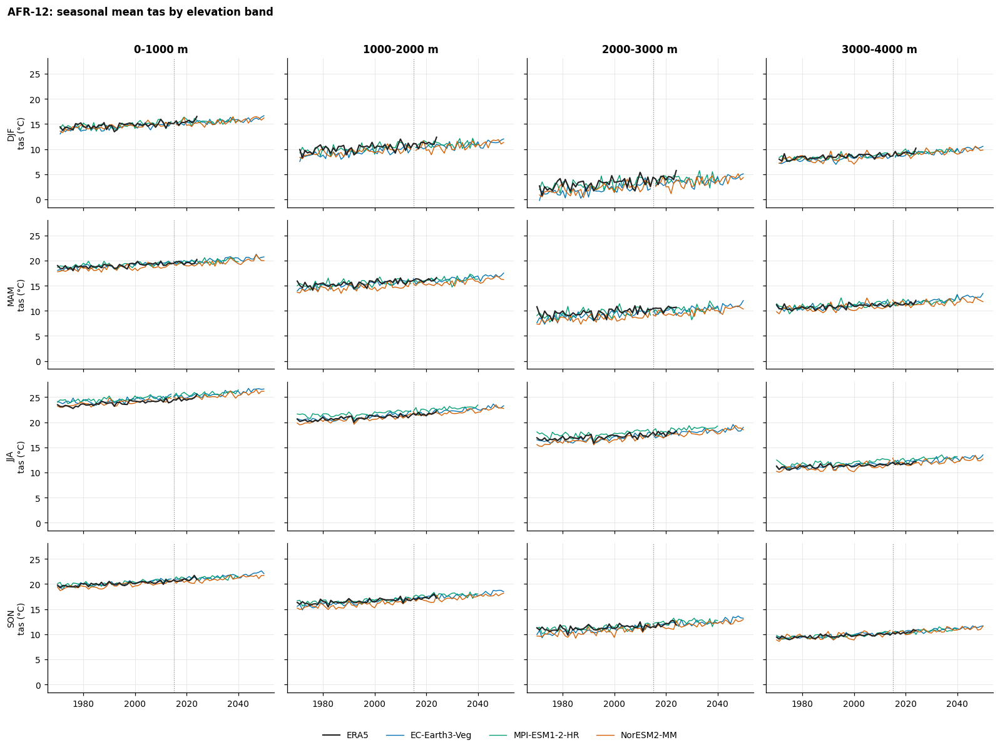

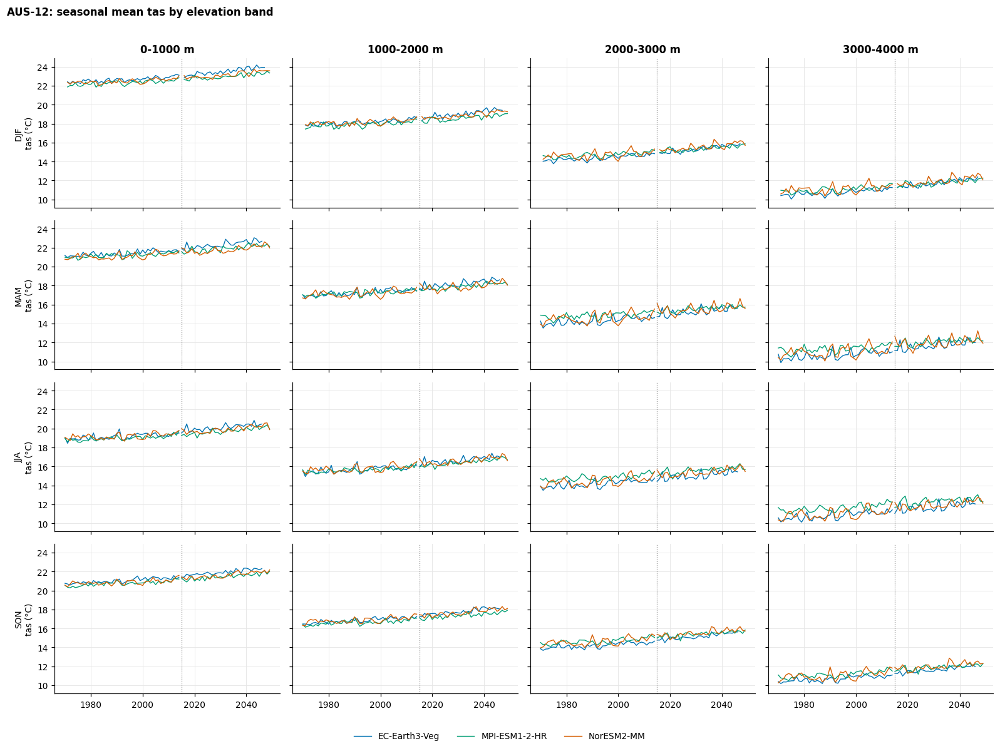

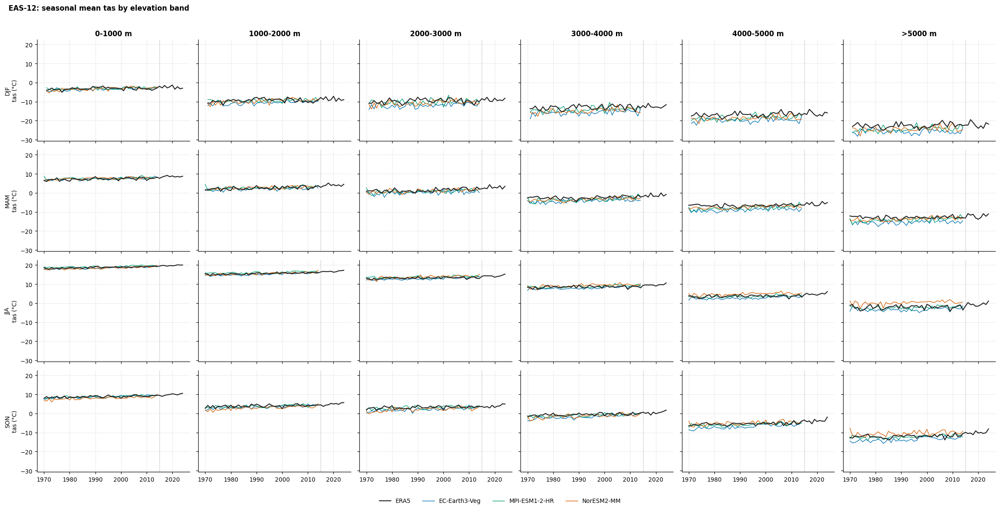

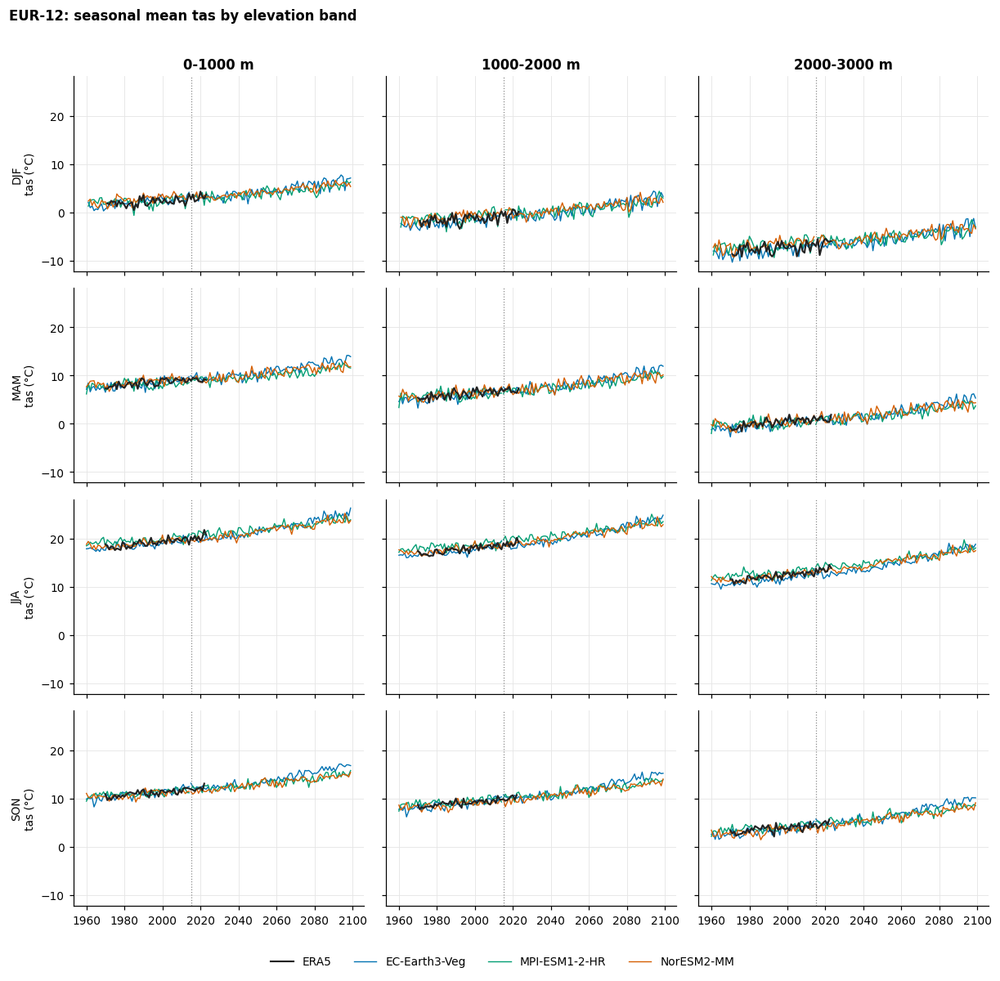

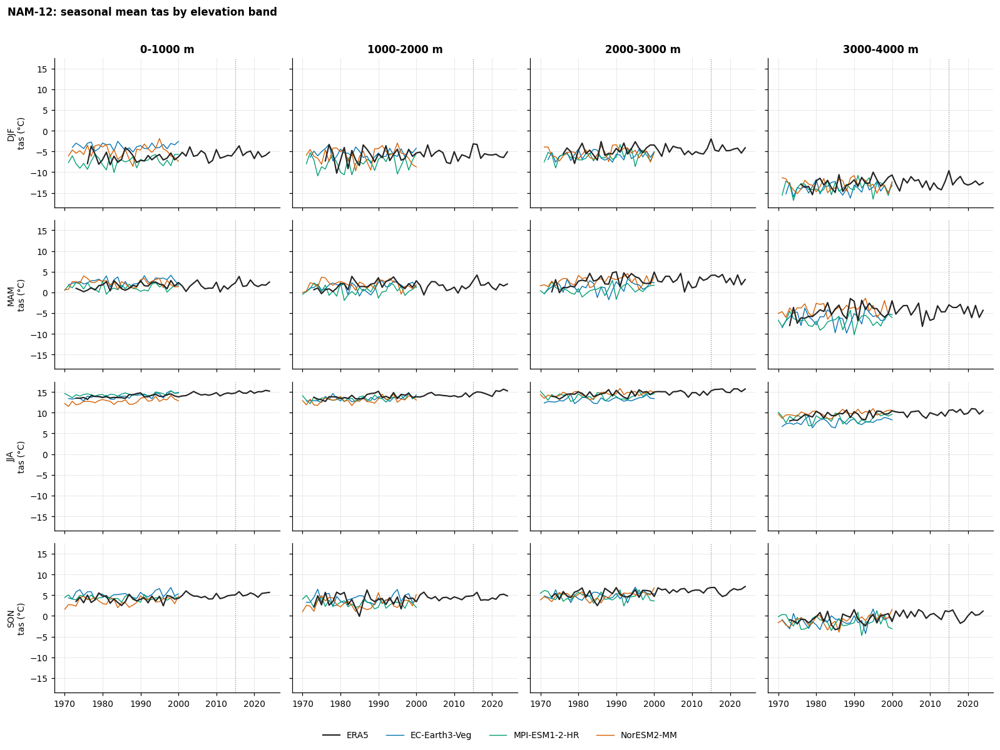

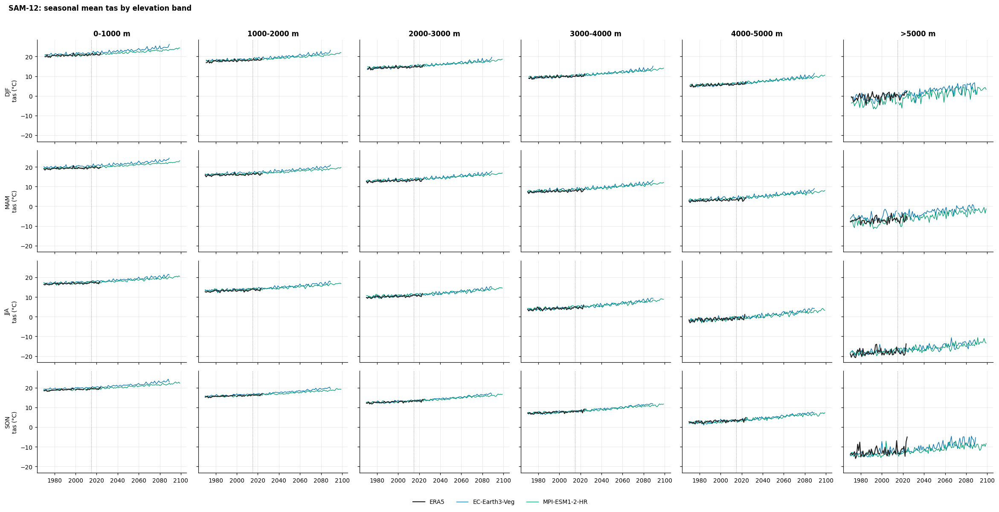

In [13]:
for dom in DOMAINS:
    band_season_plot(dom, "tas_C", "tas (°C)", "seasonal mean tas by elevation band")

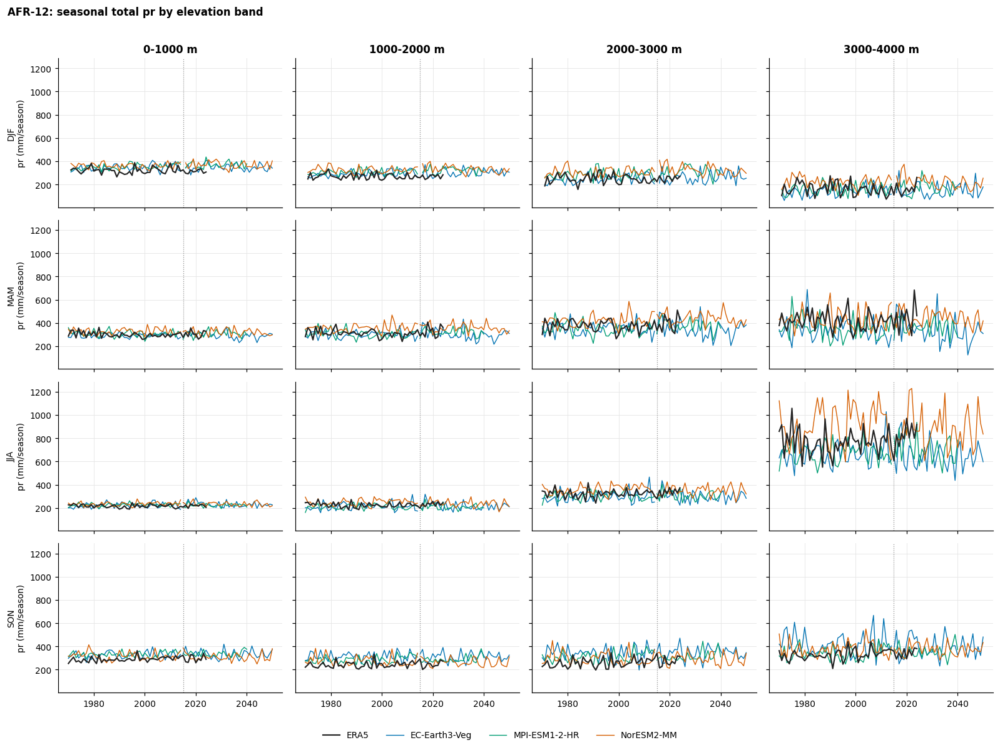

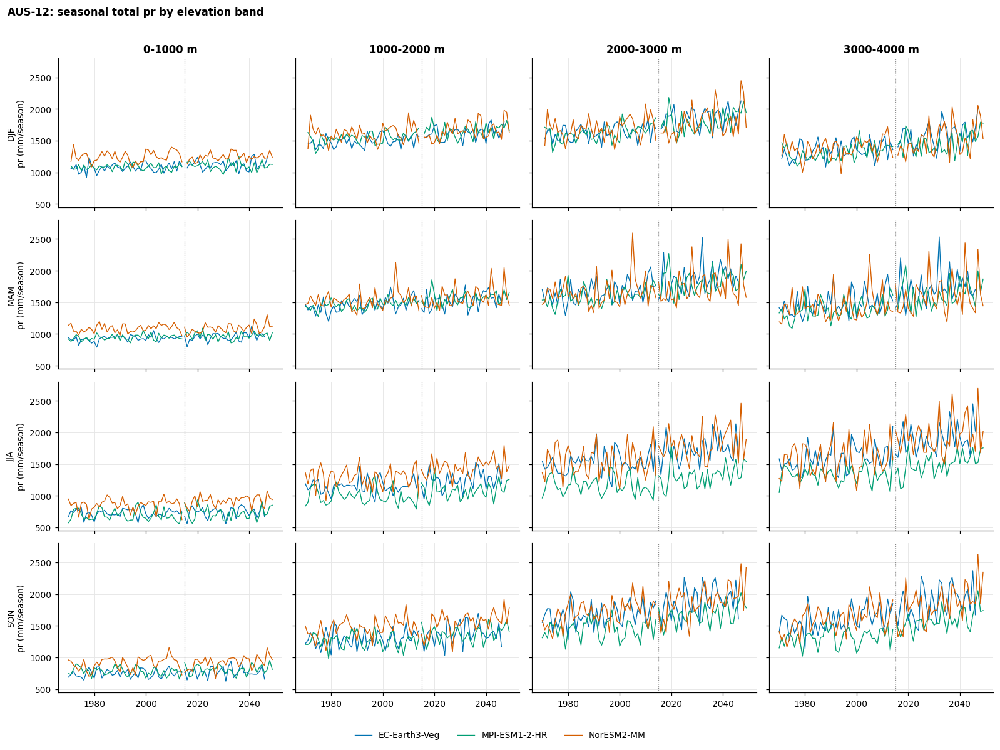

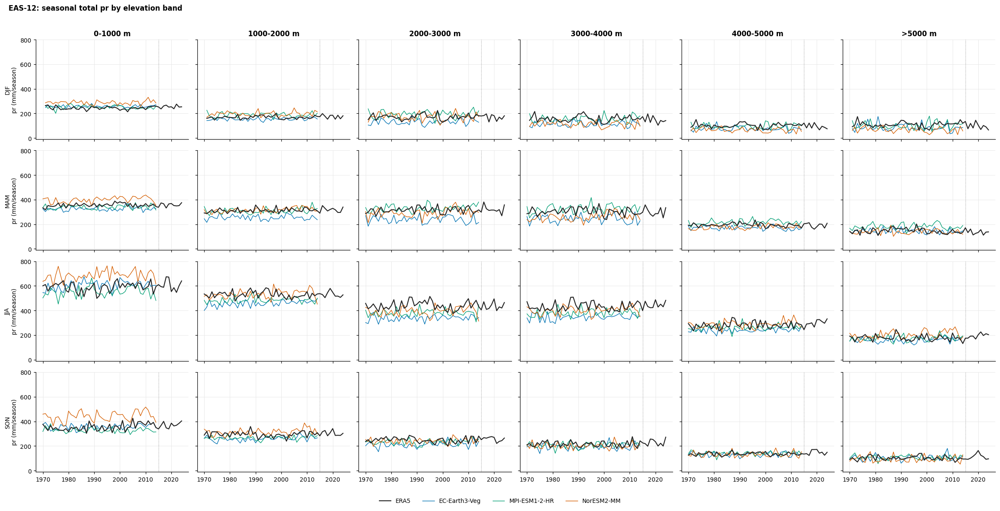

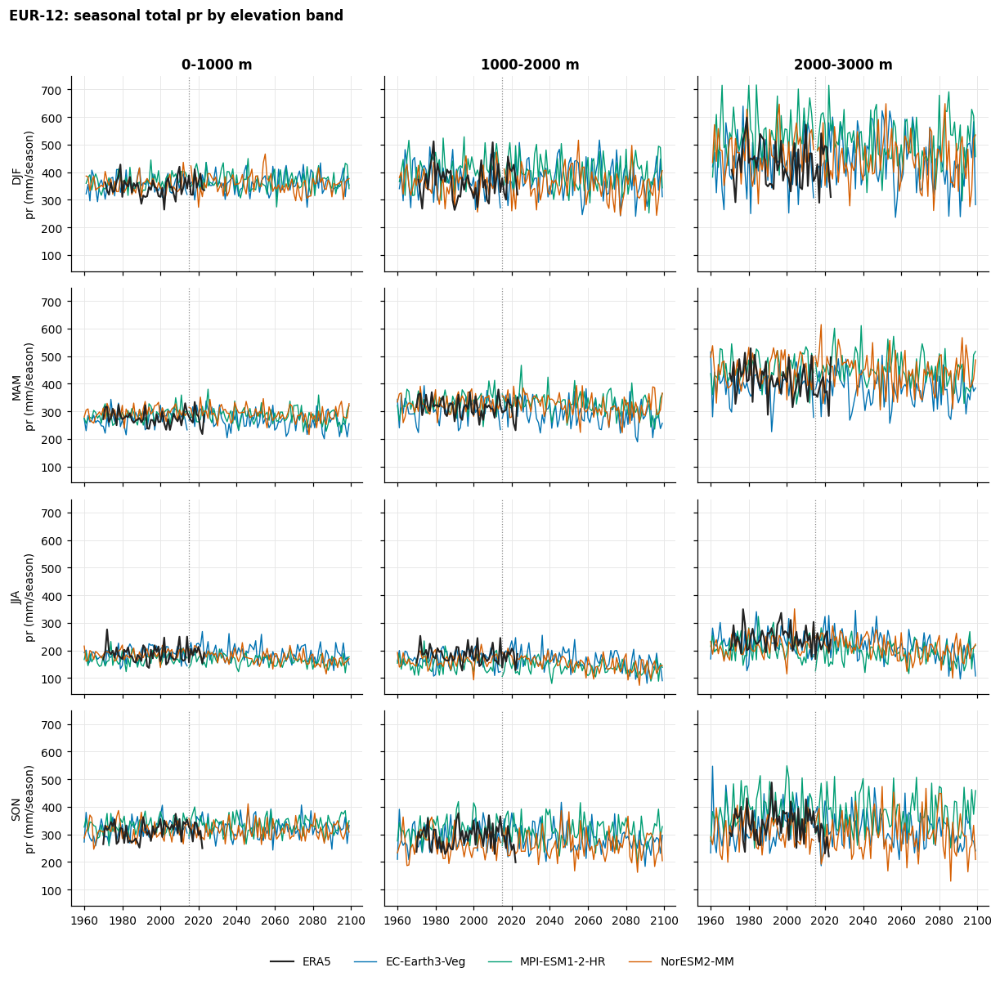

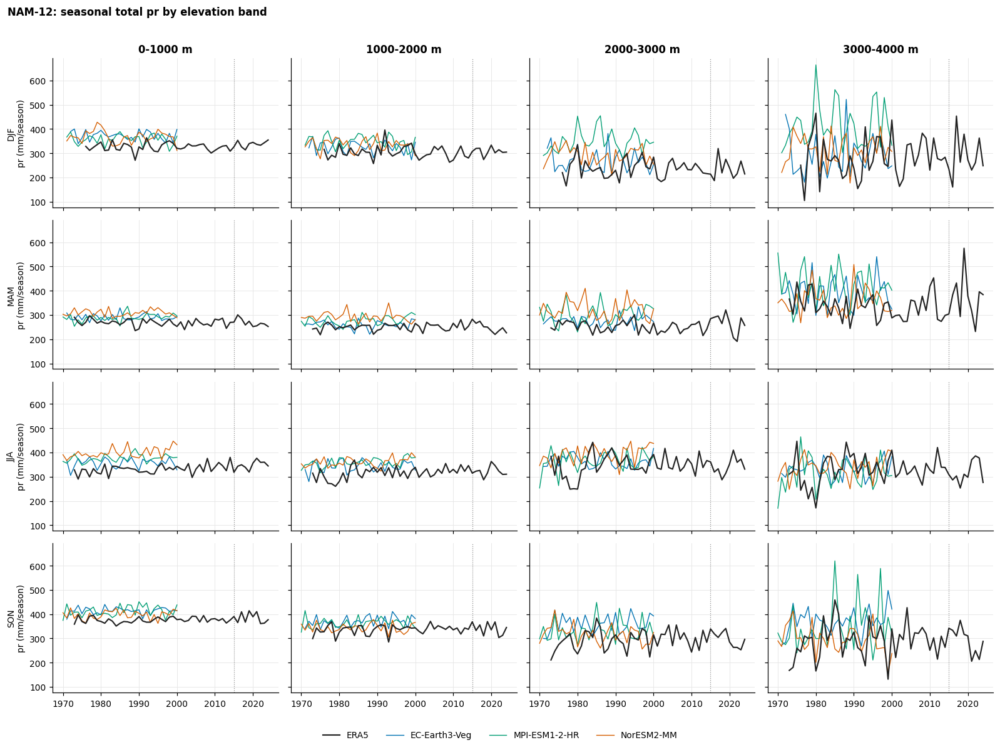

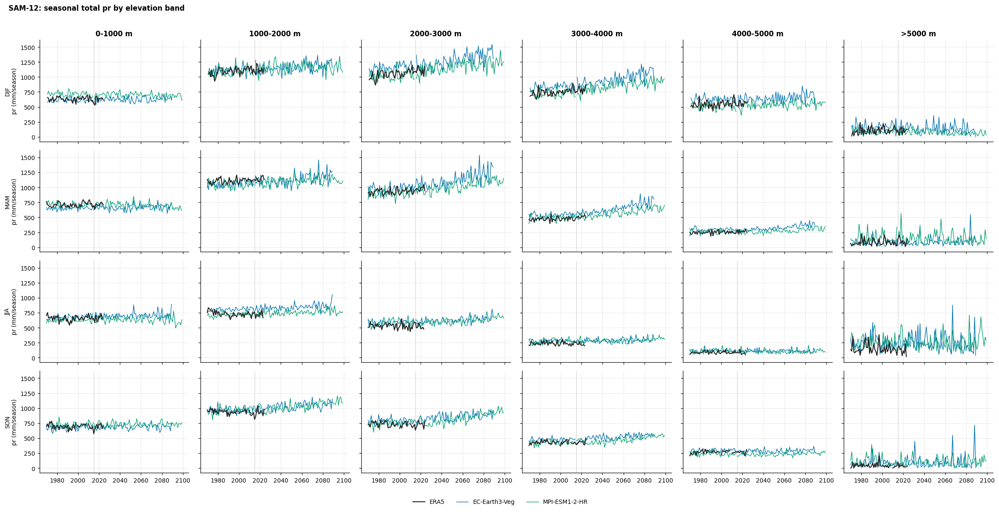

In [14]:
for dom in DOMAINS:
    band_season_plot(dom, "pr_mm", "pr (mm/season)", "seasonal total pr by elevation band")